In [2]:
import pandas as pd

df = pd.read_csv('/content/url_features_extracted1.csv')

print(df.shape)

(101219, 18)


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
print(df.columns.tolist())

['URL', 'url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars', 'ClassLabel']


In [5]:
for column in df.columns:
    print(column)

URL
url_length
has_ip_address
dot_count
https_flag
url_entropy
token_count
subdomain_count
query_param_count
tld_length
path_length
has_hyphen_in_domain
number_of_digits
tld_popularity
suspicious_file_extension
domain_name_length
percentage_numeric_chars
ClassLabel


In [6]:
df.head()

,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://keraekken-loagginnusa.godaddysites.com/,47,0,2,1,4.250669,6,1,1,3,1,1,0,1,0,12,0.0,0.0
1,https://metamsk01lgiix.godaddysites.com/,40,0,2,1,4.196439,6,1,1,3,1,0,2,1,0,12,5.0,0.0
2,http://myglobaltech.in/,23,0,1,0,3.936180,5,0,1,2,1,0,0,0,0,12,0.0,0.0
3,http://djtool-for-spotify.com/,30,0,1,0,3.894740,5,0,1,3,1,1,0,1,0,18,0.0,0.0
4,https://scearmcoommunnlty.com/invent/freind/get,47,0,1,1,4.143127,7,0,1,3,18,0,0,1,0,17,0.0,0.0


In [7]:
print("Dataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset shape:
(101219, 18)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101219 entries, 0 to 101218
Data columns (total 18 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   URL                        101219 non-null  object 
 1   url_length                 101219 non-null  int64  
 2   has_ip_address             101219 non-null  int64  
 3   dot_count                  101219 non-null  int64  
 4   https_flag                 101219 non-null  int64  
 5   url_entropy                101219 non-null  float64
 6   token_count                101219 non-null  int64  
 7   subdomain_count            101219 non-null  int64  
 8   query_param_count          101219 non-null  int64  
 9   tld_length                 101219 non-null  int64  
 10  path_length                101219 non-null  int64  
 11  has_hyphen_in_domain       101219 non-null  int64  
 12  number_of_digits           101219 no

In [8]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nClass distribution:")
print(df['ClassLabel'].value_counts())

print("\nClass distribution (%):")
print(df['ClassLabel'].value_counts(normalize=True) * 100)

Missing values:
URL                          0
url_length                   0
has_ip_address               0
dot_count                    0
https_flag                   0
url_entropy                  0
token_count                  0
subdomain_count              0
query_param_count            0
tld_length                   0
path_length                  0
has_hyphen_in_domain         0
number_of_digits             0
tld_popularity               0
suspicious_file_extension    0
domain_name_length           0
percentage_numeric_chars     0
ClassLabel                   1
dtype: int64

Duplicate rows:
346

Class distribution:
ClassLabel
0.0    63678
1.0    37540
Name: count, dtype: int64

Class distribution (%):
ClassLabel
0.0    62.911735
1.0    37.088265
Name: proportion, dtype: float64


In [9]:
# Remove rows where the target label is missing
df_clean = df.dropna(subset=['ClassLabel'])

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Reset row numbers
df_clean = df_clean.reset_index(drop=True)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())

Original dataset shape: (101219, 18)
Cleaned dataset shape: (100872, 18)

Missing values after cleaning:
0

Duplicate rows after cleaning:
0


In [10]:
# ============================================
# STEP 4: FEATURE ANALYSIS
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

# Show statistical summary of numerical features
print("Feature Statistics:")
display(df_clean.describe())

# --------------------------------------------
# Compare feature averages for each class
# --------------------------------------------

feature_columns = [
    'url_length',
    'has_ip_address',
    'dot_count',
    'https_flag',
    'url_entropy',
    'token_count',
    'subdomain_count',
    'query_param_count',
    'tld_length',
    'path_length',
    'has_hyphen_in_domain',
    'number_of_digits',
    'tld_popularity',
    'suspicious_file_extension',
    'domain_name_length',
    'percentage_numeric_chars'
]

print("\nAverage feature values by class:")
display(df_clean.groupby('ClassLabel')[feature_columns].mean())

Feature Statistics:


,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
count,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000,100872.000000
mean,35.030454,0.484931,3.008545,0.405375,3.975921,6.883347,1.512015,1.010627,5.001477,8.504203,0.043025,8.508873,0.327841,0.146820,6.294740,24.133488,0.370569
std,16.781961,0.499775,0.946061,0.490967,0.307132,1.671268,0.624530,0.203142,2.917555,14.665569,0.202914,8.545659,0.469429,0.353928,5.345684,22.489888,0.482959
min,7.000000,0.000000,0.000000,0.000000,2.521641,1.000000,-1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,0.000000,2.000000,0.000000,3.770942,5.000000,1.000000,1.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000
50%,31.000000,0.000000,3.000000,0.000000,3.936892,7.000000,2.000000,1.000000,3.000000,2.000000,0.000000,10.000000,0.000000,0.000000,3.000000,19.642857,0.000000
75%,35.000000,1.000000,4.000000,1.000000,4.100229,8.000000,2.000000,1.000000,8.000000,7.000000,0.000000,15.000000,1.000000,0.000000,10.000000,47.058824,1.000000
max,474.000000,1.000000,19.000000,1.000000,5.871503,48.000000,5.000000,14.000000,10.000000,317.000000,1.000000,164.000000,1.000000,1.000000,36.000000,65.957447,1.000000



Average feature values by class:


,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars
ClassLabel,,,,,,,,,,,,,,,,
0.0,39.432889,0.770428,3.510033,0.055346,4.045377,7.882584,1.721382,1.016868,6.341271,13.303849,0.024570,13.475902,0.114865,0.233195,4.117826,38.203536
1.0,27.552675,0.000000,2.156742,0.999920,3.857945,5.186089,1.156394,1.000027,2.725762,0.351739,0.074371,0.072097,0.689593,0.000107,9.992349,0.234733


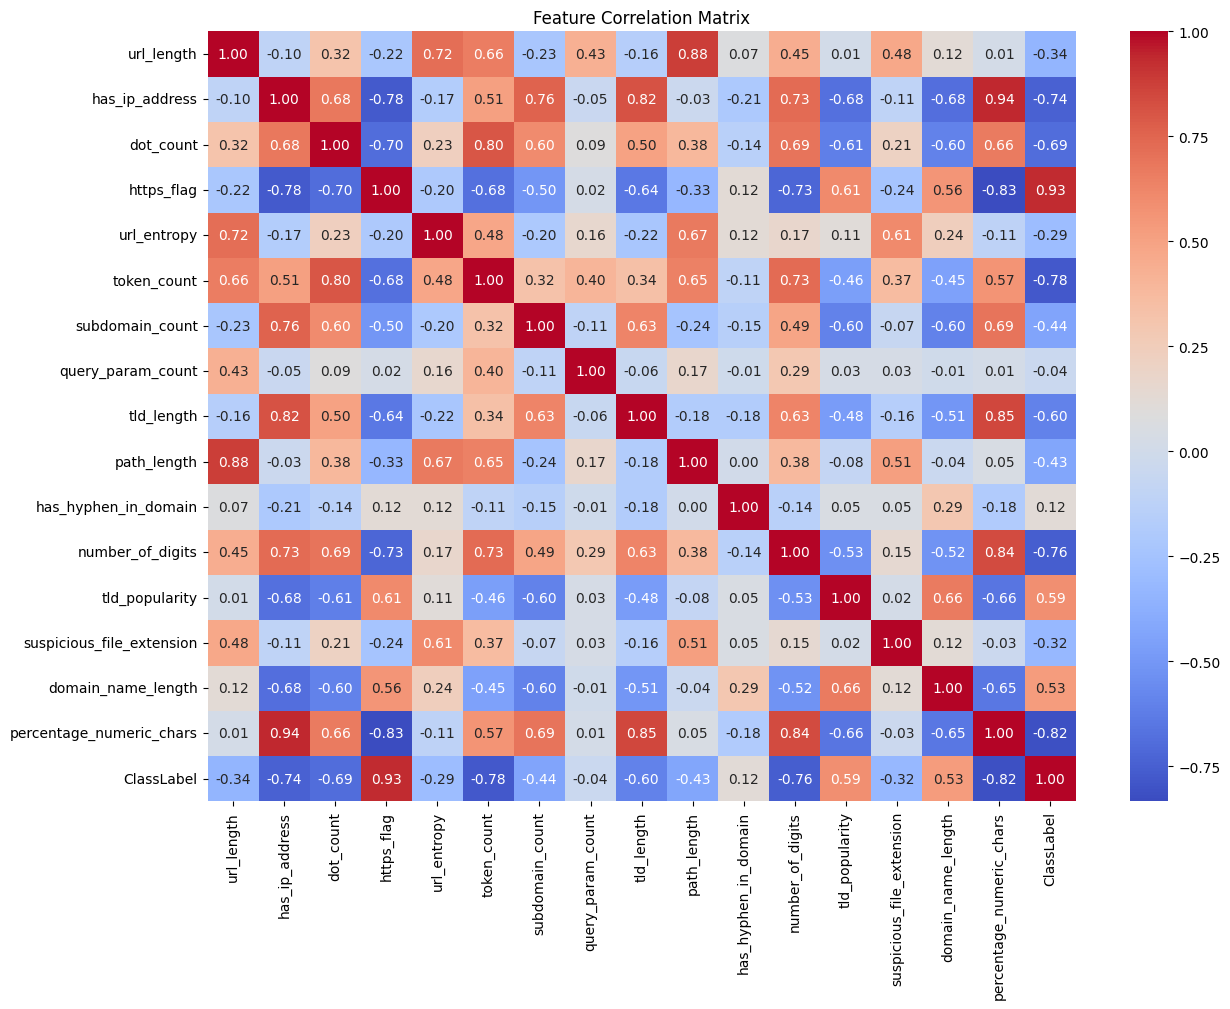

In [11]:
# ============================================
# FEATURE CORRELATION MATRIX
# ============================================

correlation = df_clean[feature_columns + ['ClassLabel']].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Matrix")
plt.show()

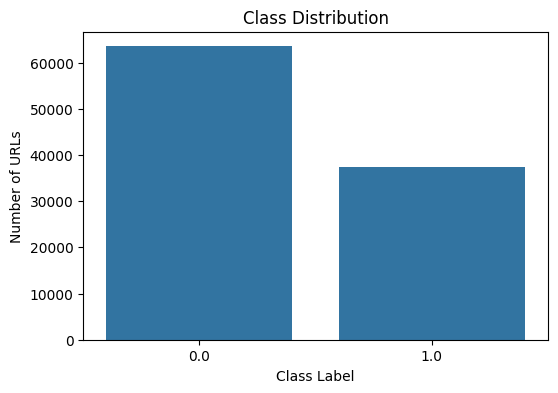

In [12]:
# ============================================
# CLASS DISTRIBUTION
# ============================================

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df_clean,
    x='ClassLabel'
)

plt.title("Class Distribution")
plt.xlabel("Class Label")
plt.ylabel("Number of URLs")

plt.show()

In [13]:
# ============================================
# STEP 5: TRAIN / TEST SPLIT
# ============================================

from sklearn.model_selection import train_test_split

# Features (remove URL and target column)
X = df_clean.drop(columns=['URL', 'ClassLabel'])

# Target
y = df_clean['ClassLabel']

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training data shape: (80697, 16)
Testing data shape: (20175, 16)

Training class distribution:
ClassLabel
0.0    50793
1.0    29904
Name: count, dtype: int64

Testing class distribution:
ClassLabel
0.0    12699
1.0     7476
Name: count, dtype: int64


In [14]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [15]:
# Make predictions on the test data
y_pred = rf_model.predict(X_test)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 20175


In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Random Forest Accuracy:", accuracy)

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Random Forest Accuracy: 0.999454770755886

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     12699
         1.0       1.00      1.00      1.00      7476

    accuracy                           1.00     20175
   macro avg       1.00      1.00      1.00     20175
weighted avg       1.00      1.00      1.00     20175


Confusion Matrix:
[[12697     2]
 [    9  7467]]


In [17]:
# Feature importance from Random Forest

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort from most important to least important
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
                      Feature  Importance
9                 path_length    0.339626
5                 token_count    0.170380
3                  https_flag    0.134320
15   percentage_numeric_chars    0.117671
11           number_of_digits    0.100386
2                   dot_count    0.044477
6             subdomain_count    0.022416
8                  tld_length    0.020406
1              has_ip_address    0.019481
14         domain_name_length    0.011521
0                  url_length    0.010752
13  suspicious_file_extension    0.003918
4                 url_entropy    0.003137
12             tld_popularity    0.001225
10       has_hyphen_in_domain    0.000189
7           query_param_count    0.000093


In [18]:
RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

In [19]:
import joblib

joblib.dump(rf_model, "phishing_random_forest.pkl")

print("Model saved successfully!")

Model saved successfully!


In [20]:
import joblib

# Load the saved Random Forest model
rf_model = joblib.load("phishing_random_forest.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [21]:
# Check the feature names expected by our model

print("Features used by the model:")
print(X_train.columns.tolist())

Features used by the model:
['url_length', 'has_ip_address', 'dot_count', 'https_flag', 'url_entropy', 'token_count', 'subdomain_count', 'query_param_count', 'tld_length', 'path_length', 'has_hyphen_in_domain', 'number_of_digits', 'tld_popularity', 'suspicious_file_extension', 'domain_name_length', 'percentage_numeric_chars']


In [22]:
# Show all feature names clearly

for i, feature in enumerate(X_train.columns, start=1):
    print(i, "->", feature)

1 -> url_length
2 -> has_ip_address
3 -> dot_count
4 -> https_flag
5 -> url_entropy
6 -> token_count
7 -> subdomain_count
8 -> query_param_count
9 -> tld_length
10 -> path_length
11 -> has_hyphen_in_domain
12 -> number_of_digits
13 -> tld_popularity
14 -> suspicious_file_extension
15 -> domain_name_length
16 -> percentage_numeric_chars


In [23]:
from urllib.parse import urlparse
import re
import math
from collections import Counter

def extract_features(url):

    parsed = urlparse(url)

    # Basic URL components
    domain = parsed.netloc
    path = parsed.path
    query = parsed.query

    # 1. URL length
    url_length = len(url)

    # 2. Check if IP address is used
    has_ip_address = 1 if re.match(
        r"^(?:\d{1,3}\.){3}\d{1,3}$", domain
    ) else 0

    # 3. Number of dots
    dot_count = url.count('.')

    # 4. HTTPS flag
    https_flag = 1 if parsed.scheme.lower() == "https" else 0

    # 5. URL entropy
    if len(url) > 0:
        counts = Counter(url)
        probabilities = [count / len(url) for count in counts.values()]
        url_entropy = -sum(p * math.log2(p) for p in probabilities)
    else:
        url_entropy = 0

    # 6. Token count
    tokens = re.split(r'[/\-.?=&_:]+', url)
    tokens = [token for token in tokens if token]
    token_count = len(tokens)

    # 7. Subdomain count
    domain_parts = domain.split('.')
    subdomain_count = max(0, len(domain_parts) - 2)

    # 8. Query parameter count
    query_param_count = 0 if not query else len(query.split('&'))

    # 9. TLD length
    tld = domain_parts[-1] if len(domain_parts) > 1 else ""
    tld_length = len(tld)

    # 10. Path length
    path_length = len(path)

    # 11. Hyphen in domain
    has_hyphen_in_domain = 1 if '-' in domain else 0

    # 12. Number of digits
    number_of_digits = sum(char.isdigit() for char in url)

    # 13. TLD popularity
    # Common TLDs are given higher values
    popular_tlds = {
        'com': 1,
        'org': 1,
        'net': 1,
        'edu': 1,
        'gov': 1,
        'in': 1,
        'co': 1
    }

    tld_popularity = popular_tlds.get(tld.lower(), 0)

    # 14. Suspicious file extension
    suspicious_extensions = [
        '.exe', '.scr', '.zip', '.rar', '.apk',
        '.bat', '.cmd', '.msi', '.dll'
    ]

    suspicious_file_extension = 1 if any(
        ext in url.lower() for ext in suspicious_extensions
    ) else 0

    # 15. Domain name length
    domain_name_length = len(domain)

    # 16. Percentage of numeric characters
    percentage_numeric_chars = (
        number_of_digits / len(url) * 100
        if len(url) > 0 else 0
    )

    # Return features in EXACT training order
    return [
        url_length,
        has_ip_address,
        dot_count,
        https_flag,
        url_entropy,
        token_count,
        subdomain_count,
        query_param_count,
        tld_length,
        path_length,
        has_hyphen_in_domain,
        number_of_digits,
        tld_popularity,
        suspicious_file_extension,
        domain_name_length,
        percentage_numeric_chars
    ]

print("Feature extraction function created successfully!")

Feature extraction function created successfully!


In [24]:
def predict_url(url):

    # Extract features from the raw URL
    features = extract_features(url)

    # Convert features into the format expected by the model
    X_new = pd.DataFrame(
        [features],
        columns=X_train.columns
    )

    # Make prediction
    prediction = rf_model.predict(X_new)[0]

    # Display result
    print("URL:", url)

    if prediction == 0:
        print("Prediction: PHISHING ⚠️")
    else:
        print("Prediction: LEGITIMATE / SAFE ✅")

    return prediction

In [25]:
test_url = "https://www.google.com"

predict_url(test_url)

URL: https://www.google.com
Prediction: LEGITIMATE / SAFE ✅


np.float64(1.0)

In [26]:
# Test the phishing detection model

test_url = "https://www.google.com"

predict_url(test_url)

URL: https://www.google.com
Prediction: LEGITIMATE / SAFE ✅


np.float64(1.0)

In [27]:
test_url = "https://www.google.com"

predict_url(test_url)

URL: https://www.google.com
Prediction: LEGITIMATE / SAFE ✅


np.float64(1.0)

In [28]:
# Test multiple URLs

test_urls = [
    "https://www.google.com",
    "https://www.youtube.com",
    "https://www.wikipedia.org",
    "http://example.com"
]

for url in test_urls:
    print("\n-----------------------------")
    predict_url(url)


-----------------------------
URL: https://www.google.com
Prediction: LEGITIMATE / SAFE ✅

-----------------------------
URL: https://www.youtube.com
Prediction: LEGITIMATE / SAFE ✅

-----------------------------
URL: https://www.wikipedia.org
Prediction: LEGITIMATE / SAFE ✅

-----------------------------
URL: http://example.com
Prediction: PHISHING ⚠️


In [29]:
# Check the extracted features for a normal URL

url = "https://www.google.com"

features = extract_features(url)

print("Features extracted from:", url)
for name, value in zip(X_train.columns, features):
    print(name, "=", value)

Features extracted from: https://www.google.com
url_length = 22
has_ip_address = 0
dot_count = 2
https_flag = 1
url_entropy = 3.6635327548042547
token_count = 4
subdomain_count = 1
query_param_count = 0
tld_length = 3
path_length = 0
has_hyphen_in_domain = 0
number_of_digits = 0
tld_popularity = 1
suspicious_file_extension = 0
domain_name_length = 14
percentage_numeric_chars = 0.0


In [30]:
print(df["ClassLabel"].value_counts())
print(df.groupby("ClassLabel")["url_length"].mean())

ClassLabel
0.0    63678
1.0    37540
Name: count, dtype: int64
ClassLabel
0.0    39.411869
1.0    27.680874
Name: url_length, dtype: float64


In [31]:
print(df[df["ClassLabel"] == 0]["URL"].head(10).to_string(index=False))
print("\n-----------------------------\n")
print(df[df["ClassLabel"] == 1]["URL"].head(10).to_string(index=False))

   https://keraekken-loagginnusa.godaddysites.com/
          https://metamsk01lgiix.godaddysites.com/
                           http://myglobaltech.in/
                    http://djtool-for-spotify.com/
   https://scearmcoommunnlty.com/invent/freind/get
http://instagramtick-git-master-behhruzs-projec...
http://bafybeicsc2iofzskpmb56uzh72jirndpnmcs42v...
             http://login-page-105531.square.site/
                  http://bt-101274.weeblysite.com/
                      http://molina-c2f.pages.dev/

-----------------------------

    https://stackoverflow.com/questions/tagged/php
https://stackoverflow.com/questions/tagged/micr...
    https://stackoverflow.com/questions/tagged/sql
https://stackoverflow.com/questions/79030270/ho...
   https://stackoverflow.com/questions/tagged/java
   https://stackoverflow.com/questions/tagged/iwyu
https://stackoverflow.com/questions/tagged/android
https://stackoverflow.com/questions/tagged/depe...
https://stackoverflow.com/questions/tagged/mach...

In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Predict on the test dataset
y_pred = rf_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("===== MODEL EVALUATION =====")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred))

print("\n===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred))

===== MODEL EVALUATION =====
Accuracy : 0.999454770755886
Precision: 0.9997322265363503
Recall   : 0.9987961476725522
F1 Score : 0.9992639678822348

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     12699
         1.0       1.00      1.00      1.00      7476

    accuracy                           1.00     20175
   macro avg       1.00      1.00      1.00     20175
weighted avg       1.00      1.00      1.00     20175


===== CONFUSION MATRIX =====
[[12697     2]
 [    9  7467]]


===== FEATURE IMPORTANCE =====
                      Feature  Importance
9                 path_length    0.339626
5                 token_count    0.170380
3                  https_flag    0.134320
15   percentage_numeric_chars    0.117671
11           number_of_digits    0.100386
2                   dot_count    0.044477
6             subdomain_count    0.022416
8                  tld_length    0.020406
1              has_ip_address    0.019481
14         domain_name_length    0.011521
0                  url_length    0.010752
13  suspicious_file_extension    0.003918
4                 url_entropy    0.003137
12             tld_popularity    0.001225
10       has_hyphen_in_domain    0.000189
7           query_param_count    0.000093


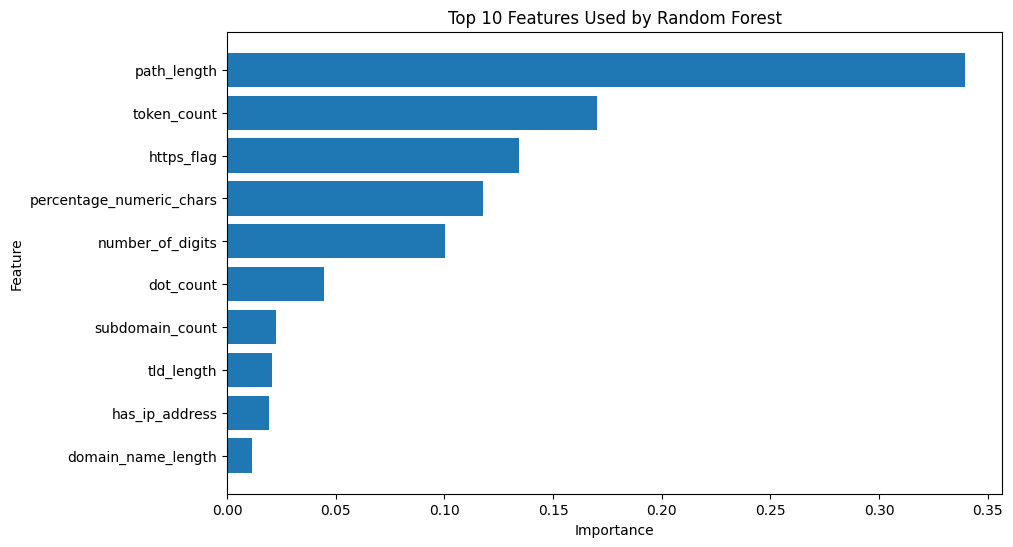

In [33]:
# ==========================================
# RANDOM FOREST FEATURE IMPORTANCE
# ==========================================

import matplotlib.pyplot as plt
import pandas as pd

# Get feature importance from Random Forest
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display feature importance
print("===== FEATURE IMPORTANCE =====")
print(feature_importance)

# Plot top features
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"].head(10)[::-1],
    feature_importance["Importance"].head(10)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Used by Random Forest")

plt.show()

In [34]:
!pip install gradio -q

In [35]:
import gradio as gr

def check_url(url):
    prediction = predict_url(url)

    if prediction == 0:
        return "⚠️ PHISHING URL"
    else:
        return "✅ LEGITIMATE / SAFE URL"


demo = gr.Interface(
    fn=check_url,
    inputs=gr.Textbox(
        label="Enter URL",
        placeholder="https://example.com"
    ),
    outputs=gr.Textbox(
        label="Prediction"
    ),
    title="Phishing URL Detection",
    description="Enter a URL to detect whether it is phishing or legitimate."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5ae82690c1a8e48e14.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# New section